In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv(
    "sales.csv",
    encoding="unicode_escape"
)

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [5]:
# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Display column names
print("\nColumns:")
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.00000,2823.000000
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,2.717676,7.092455,2003.81509,100.715551
std,92.085478,9.741443,20.174277,4.225841,1841.865106,1.203878,3.656633,0.69967,40.187912
min,10100.000000,6.000000,26.880000,1.000000,482.130000,1.000000,1.000000,2003.00000,33.000000
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,2.000000,4.000000,2003.00000,68.000000
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,3.000000,8.000000,2004.00000,99.000000
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,4.000000,11.000000,2004.00000,124.000000
max,10425.000000,97.000000,100.000000,18.000000,14082.800000,4.000000,12.000000,2005.00000,214.000000



Missing Values:
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

Duplicate Records: 0

Columns:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRS

In [6]:
# Remove duplicate records
df.drop_duplicates(inplace=True)

# Select numerical features
features = [
    'QUANTITYORDERED',
    'PRICEEACH',
    'SALES'
]

# Check missing values
print(df[features].isnull().sum())

# Fill missing values with median
for col in features:
    df[col] = df[col].fillna(df[col].median())

# Create feature dataset
X = df[features]

print("Selected Features:")
display(X.head())

print("Shape:", X.shape)

QUANTITYORDERED    0
PRICEEACH          0
SALES              0
dtype: int64
Selected Features:


,QUANTITYORDERED,PRICEEACH,SALES
0,30,95.70,2871.00
1,34,81.35,2765.90
2,41,94.74,3884.34
3,45,83.26,3746.70
4,49,100.00,5205.27


Shape: (2823, 3)


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")

Feature scaling completed!


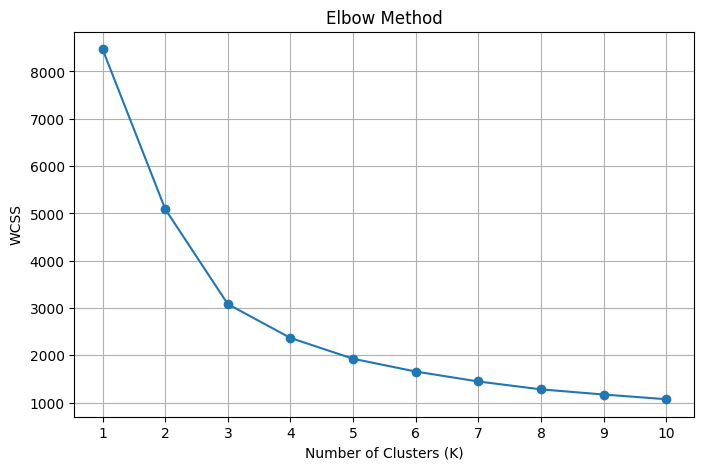

In [8]:
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [9]:
# Select optimal number of clusters
optimal_k = 3

# Create K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Fit model and predict clusters
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

print("\nCluster Distribution:")
print(df['KMeans_Cluster'].value_counts())

K-Means clustering completed!

Cluster Distribution:
KMeans_Cluster
2    1035
1     907
0     881
Name: count, dtype: int64


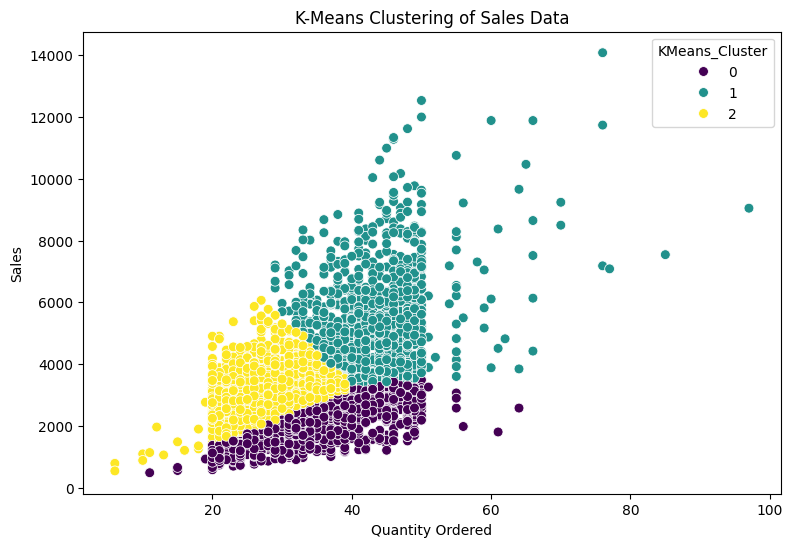

In [10]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='QUANTITYORDERED',
    y='SALES',
    hue='KMeans_Cluster',
    palette='viridis',
    s=50
)

plt.title("K-Means Clustering of Sales Data")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

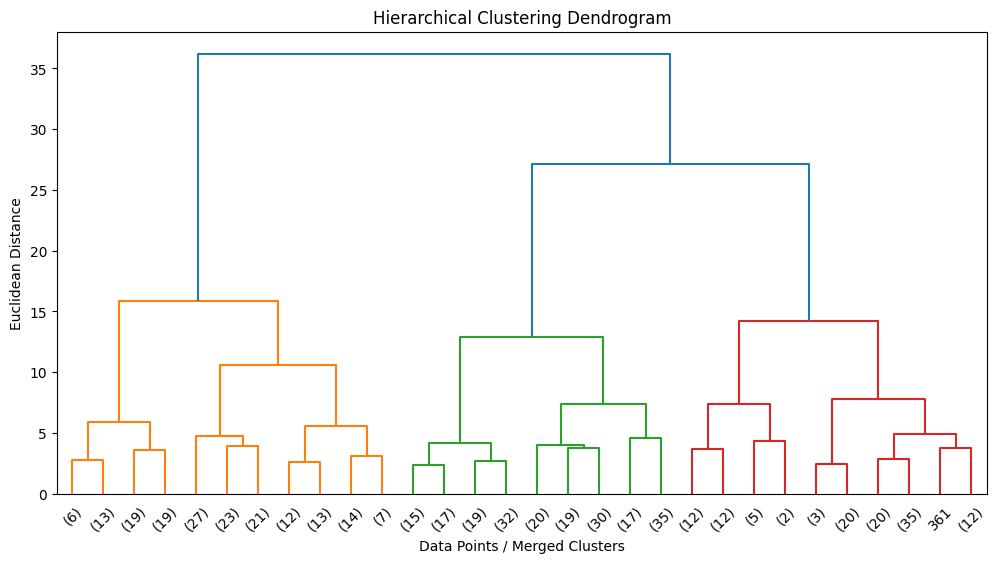

In [11]:
# Select sample for dendrogram
sample_data = X_scaled[
    np.random.RandomState(42).choice(
        len(X_scaled),
        size=min(500, len(X_scaled)),
        replace=False
    )
]

# Generate linkage matrix
linked = linkage(
    sample_data,
    method='ward'
)

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points / Merged Clusters")
plt.ylabel("Euclidean Distance")

plt.show()

In [12]:
# Create hierarchical clustering model
hc = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage='ward'
)

# Fit model and predict clusters
df['Hierarchical_Cluster'] = hc.fit_predict(X_scaled)

print("Hierarchical clustering completed!")

print("\nCluster Distribution:")
print(df['Hierarchical_Cluster'].value_counts())

Hierarchical clustering completed!

Cluster Distribution:
Hierarchical_Cluster
2    1124
0    1014
1     685
Name: count, dtype: int64


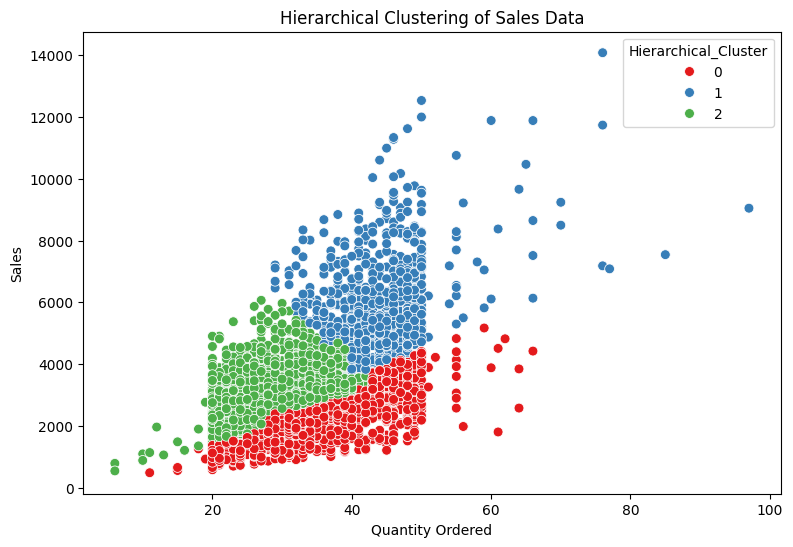

In [13]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='QUANTITYORDERED',
    y='SALES',
    hue='Hierarchical_Cluster',
    palette='Set1',
    s=50
)

plt.title("Hierarchical Clustering of Sales Data")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")

plt.show()

In [14]:
print("K-Means Cluster Distribution:")
print(df['KMeans_Cluster'].value_counts())

print("\nHierarchical Cluster Distribution:")
print(df['Hierarchical_Cluster'].value_counts())

# Compare average sales in each cluster
print("\nK-Means Cluster Analysis:")
display(
    df.groupby('KMeans_Cluster')[features].mean().round(2)
)

print("\nHierarchical Cluster Analysis:")
display(
    df.groupby('Hierarchical_Cluster')[features].mean().round(2)
)

K-Means Cluster Distribution:
KMeans_Cluster
2    1035
1     907
0     881
Name: count, dtype: int64

Hierarchical Cluster Distribution:
Hierarchical_Cluster
2    1124
0    1014
1     685
Name: count, dtype: int64

K-Means Cluster Analysis:


,QUANTITYORDERED,PRICEEACH,SALES
KMeans_Cluster,,,
0,35.13,57.13,2009.83
1,43.85,96.64,5584.01
2,27.39,94.87,3089.15



Hierarchical Cluster Analysis:


,QUANTITYORDERED,PRICEEACH,SALES
Hierarchical_Cluster,,,
0,36.58,60.35,2238.07
1,44.08,99.45,6081.75
2,28.27,95.06,3200.38
